In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel(
    "all_data_M_2023.xlsx",
    sheet_name="All May 2023 data",
    usecols=[
        "AREA_TITLE",
        "NAICS",
        "OCC_CODE",
        "OCC_TITLE",
        "O_GROUP",
        "TOT_EMP"
    ]
)

print("Dataset loaded successfully!")
print(df.shape)
df.head()

In [1]:
print("Jupyter is working")


Jupyter is working


In [3]:
import pandas as pd

df = pd.read_excel(
    "all_data_M_2023.xlsx",
    sheet_name="All May 2023 data",
    nrows=100
)

print(df.shape)
df.head()

(100, 32)


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


In [4]:
df = pd.read_excel(
    "all_data_M_2023.xlsx",
    sheet_name="All May 2023 data",
    usecols=[
        "AREA_TITLE",
        "NAICS",
        "OCC_CODE",
        "OCC_TITLE",
        "O_GROUP",
        "TOT_EMP"
    ]
)

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(413327, 6)


In [5]:
selected_occupations = [
    "Data Scientists",
    "Software Developers",
    "Computer and Information Research Scientists",
    "Information Security Analysts",
    "Computer Programmers"
]

pie_data = df[
    (df["AREA_TITLE"] == "U.S.") &
    (df["NAICS"].astype(str).isin(["0", "000000"])) &
    (df["O_GROUP"] == "detailed") &
    (df["OCC_TITLE"].isin(selected_occupations))
].copy()

pie_data["TOT_EMP"] = pd.to_numeric(
    pie_data["TOT_EMP"], errors="coerce"
)

print(pie_data[["OCC_TITLE", "TOT_EMP"]])

                                        OCC_TITLE  TOT_EMP
136                 Information Security Analysts   175350
138  Computer and Information Research Scientists    35210
148                          Computer Programmers   120370
149                           Software Developers  1656880
165                               Data Scientists   192710


In [6]:
df[
    (df["AREA_TITLE"] == "U.S.") &
    (df["OCC_TITLE"].str.contains("Data Scientist", case=False, na=False))
][["NAICS", "OCC_CODE", "OCC_TITLE", "O_GROUP", "TOT_EMP"]].head(15)

,NAICS,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP
164,000000,15-2050,Data Scientists,broad,192710
165,000000,15-2051,Data Scientists,detailed,192710
1562,000001,15-2050,Data Scientists,broad,184720
1563,000001,15-2051,Data Scientists,detailed,184720
3222,21,15-2050,Data Scientists,broad,360
3223,21,15-2051,Data Scientists,detailed,360
3750,22,15-2050,Data Scientists,broad,810
3751,22,15-2051,Data Scientists,detailed,810
4278,23,15-2050,Data Scientists,broad,440
4279,23,15-2051,Data Scientists,detailed,440


In [7]:
pie_data = pie_data.dropna(subset=["TOT_EMP"])

pie_data["Percentage"] = (
    pie_data["TOT_EMP"] / pie_data["TOT_EMP"].sum() * 100
)

print(
    pie_data[["OCC_TITLE", "TOT_EMP", "Percentage"]]
    .sort_values("TOT_EMP", ascending=False)
    .to_string(index=False)
)

                                   OCC_TITLE  TOT_EMP  Percentage
                         Software Developers  1656880   75.985545
                             Data Scientists   192710    8.837800
               Information Security Analysts   175350    8.041660
                        Computer Programmers   120370    5.520243
Computer and Information Research Scientists    35210    1.614752


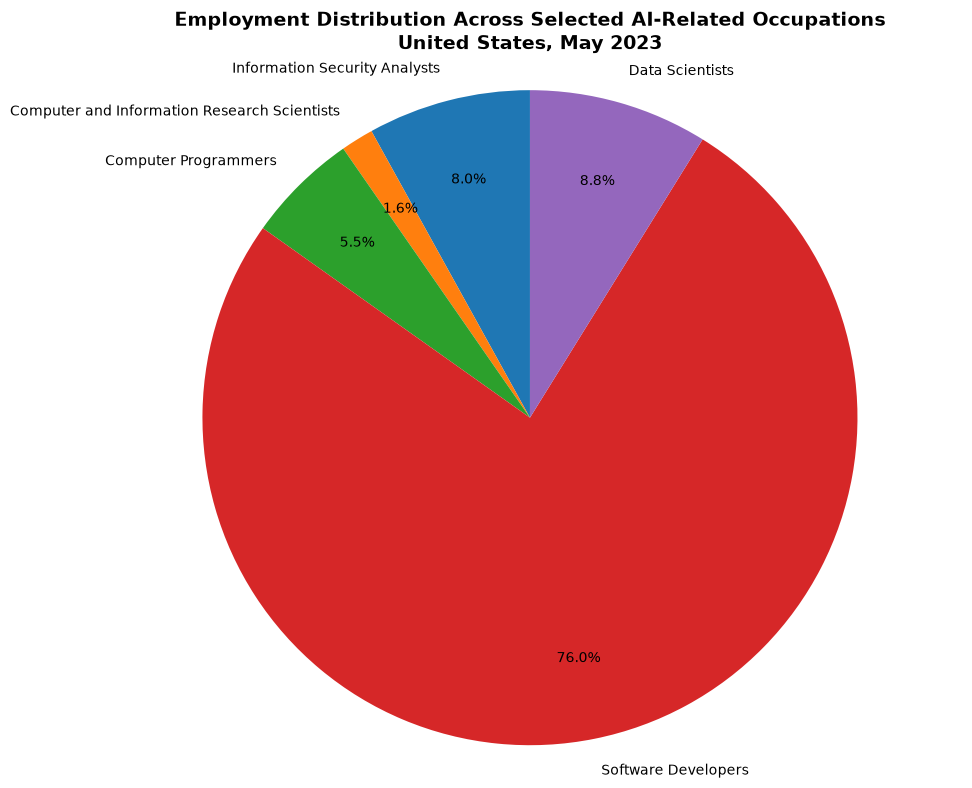

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.pie(
    pie_data["TOT_EMP"],
    labels=pie_data["OCC_TITLE"],
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.75
)

plt.title(
    "Employment Distribution Across Selected AI-Related Occupations\n"
    "United States, May 2023",
    fontsize=14,
    fontweight="bold"
)

plt.axis("equal")
plt.tight_layout()
plt.show()

In [9]:
salary_df = pd.read_excel(
    "all_data_M_2023.xlsx",
    sheet_name="All May 2023 data",
    usecols=[
        "AREA_TITLE",
        "NAICS",
        "OCC_TITLE",
        "O_GROUP",
        "A_MEAN"
    ]
)

print("Salary data loaded successfully!")
print(salary_df.shape)

Salary data loaded successfully!
(413327, 5)


In [10]:
salary_data = salary_df[
    (salary_df["AREA_TITLE"] == "U.S.") &
    (salary_df["NAICS"].astype(str).isin(["0", "000000"])) &
    (salary_df["O_GROUP"] == "detailed") &
    (salary_df["OCC_TITLE"].isin(selected_occupations))
].copy()

salary_data["A_MEAN"] = pd.to_numeric(
    salary_data["A_MEAN"],
    errors="coerce"
)

salary_data = salary_data.dropna(subset=["A_MEAN"])
salary_data = salary_data.sort_values("A_MEAN")

print(salary_data[["OCC_TITLE", "A_MEAN"]])

                                        OCC_TITLE  A_MEAN
148                          Computer Programmers  107750
165                               Data Scientists  119040
136                 Information Security Analysts  124740
149                           Software Developers  138110
138  Computer and Information Research Scientists  157160


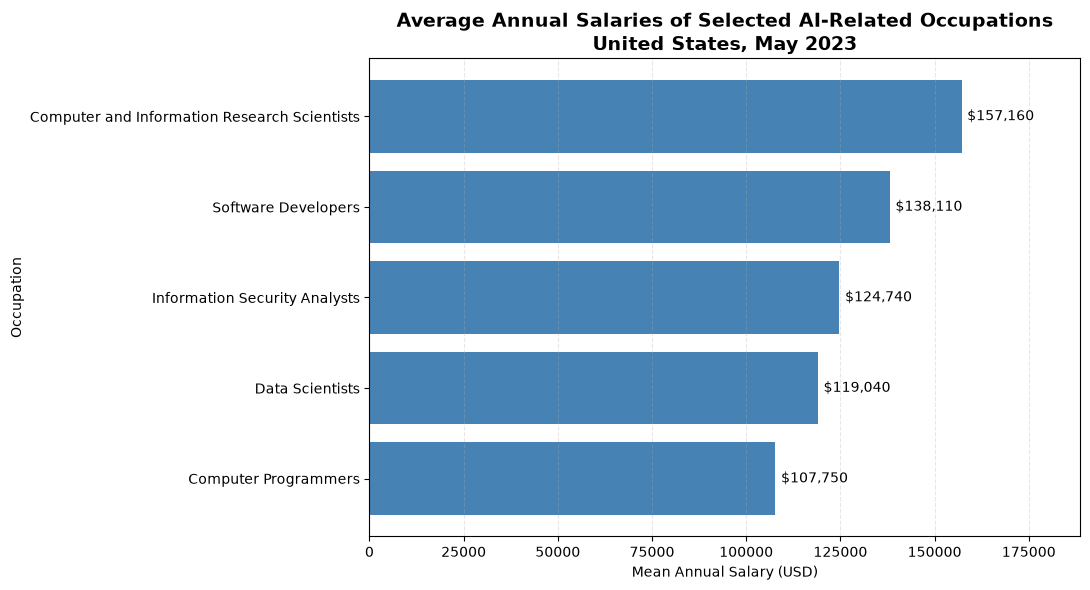

In [11]:
plt.figure(figsize=(11, 6))

bars = plt.barh(
    salary_data["OCC_TITLE"],
    salary_data["A_MEAN"],
    color="steelblue"
)
plt.xlabel("Mean Annual Salary (USD)")
plt.ylabel("Occupation")
plt.title(
    "Average Annual Salaries of Selected AI-Related Occupations\n"
    "United States, May 2023",
    fontsize=14,
    fontweight="bold"
)
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 1500,
        bar.get_y() + bar.get_height() / 2,
        f"${width:,.0f}",
        va="center"
    )
plt.xlim(0, salary_data["A_MEAN"].max() * 1.2)
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
scatter_data = pd.merge(
    pie_data[["OCC_TITLE", "TOT_EMP"]],
    salary_data[["OCC_TITLE", "A_MEAN"]],
    on="OCC_TITLE"
)

print(scatter_data)

                                      OCC_TITLE  TOT_EMP  A_MEAN
0                 Information Security Analysts   175350  124740
1  Computer and Information Research Scientists    35210  157160
2                          Computer Programmers   120370  107750
3                           Software Developers  1656880  138110
4                               Data Scientists   192710  119040


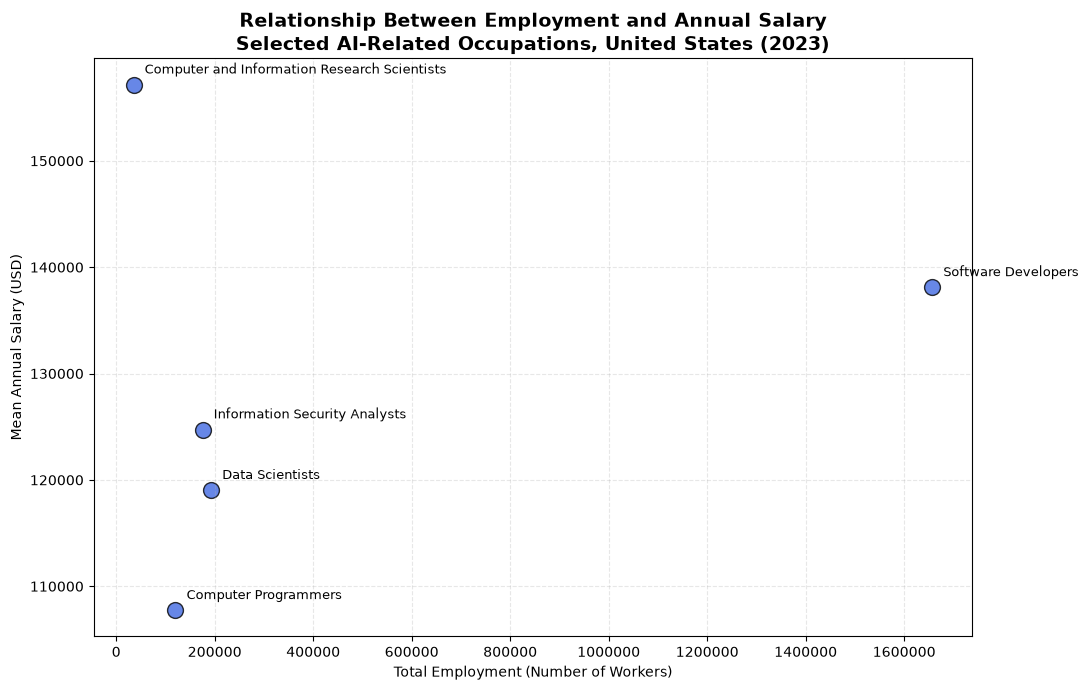

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))
plt.scatter(
    scatter_data["TOT_EMP"],
    scatter_data["A_MEAN"],
    color="royalblue",
    s=130,
    alpha=0.8,
    edgecolors="black"
)
for i, row in scatter_data.iterrows():
    plt.annotate(
        row["OCC_TITLE"],
        (row["TOT_EMP"], row["A_MEAN"]),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("Total Employment (Number of Workers)")
plt.ylabel("Mean Annual Salary (USD)")
plt.title(
    "Relationship Between Employment and Annual Salary\n"
    "Selected AI-Related Occupations, United States (2023)",
    fontsize=14,
    fontweight="bold"
)
plt.grid(True, linestyle="--", alpha=0.3)


plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

In [14]:
state_df = pd.read_excel(
    "all_data_M_2023.xlsx",
    sheet_name="All May 2023 data",
    usecols=[
        "AREA_TYPE",
        "AREA_TITLE",
        "NAICS",
        "OCC_TITLE",
        "O_GROUP",
        "A_MEAN"
    ]
)

print("State salary data loaded!")
print(state_df.shape)

State salary data loaded!
(413327, 6)


In [15]:
box_data = state_df[
    (state_df["AREA_TYPE"] == 2) &
    (state_df["NAICS"].astype(str).isin(["0", "000000"])) &
    (state_df["O_GROUP"] == "detailed") &
    (state_df["OCC_TITLE"].isin(selected_occupations))
].copy()

box_data["A_MEAN"] = pd.to_numeric(
    box_data["A_MEAN"],
    errors="coerce"
)

box_data = box_data.dropna(subset=["A_MEAN"])

print(box_data.groupby("OCC_TITLE")["A_MEAN"].agg(
    ["count", "min", "median", "max"]
))

                                              count      min    median  \
OCC_TITLE                                                                
Computer Programmers                             49  65320.0   97480.0   
Computer and Information Research Scientists     42  88770.0  131240.0   
Data Scientists                                  51  72220.0  107000.0   
Information Security Analysts                    50  90600.0  112935.0   
Software Developers                              51  88130.0  123700.0   

                                                   max  
OCC_TITLE                                               
Computer Programmers                          158520.0  
Computer and Information Research Scientists  202910.0  
Data Scientists                               148730.0  
Information Security Analysts                 148090.0  
Software Developers                           173780.0  


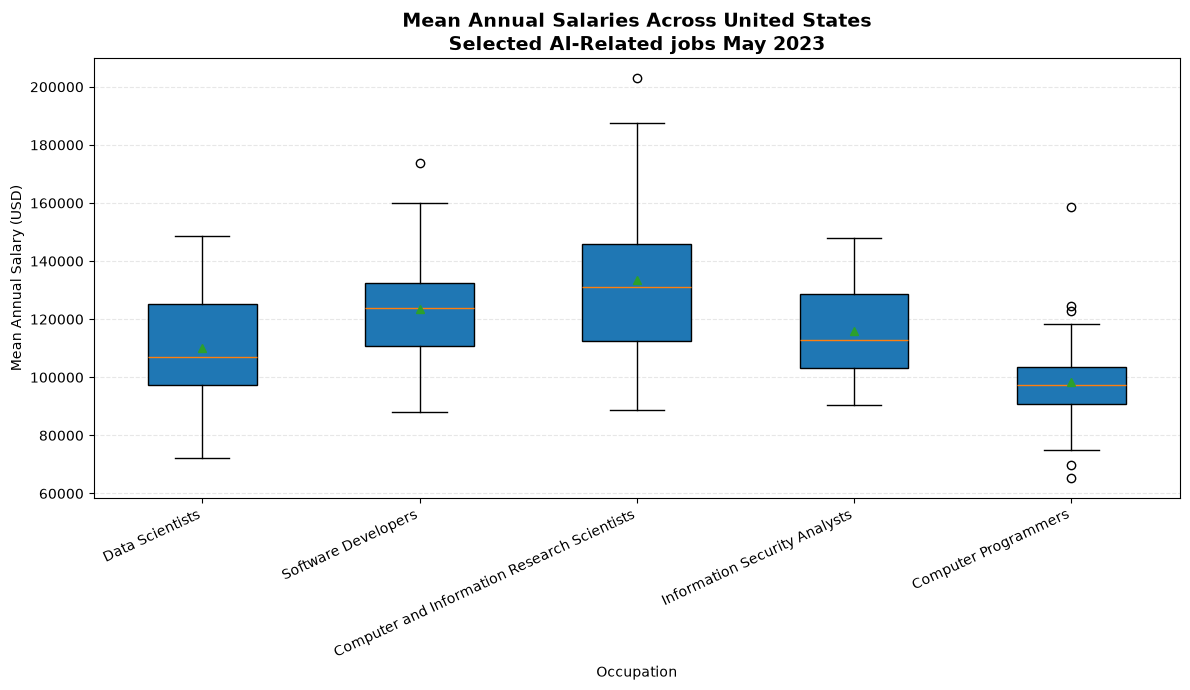

In [17]:
import matplotlib.pyplot as plt

box_occupations = [
    "Data Scientists",
    "Software Developers",
    "Computer and Information Research Scientists",
    "Information Security Analysts",
    "Computer Programmers"
]

salary_groups = [
    box_data.loc[
        box_data["OCC_TITLE"] == occupation,
        "A_MEAN"
    ].dropna().values
    for occupation in box_occupations
]

plt.figure(figsize=(12, 7))

plt.boxplot(
    salary_groups,
    tick_labels=box_occupations,
    patch_artist=True,
    showmeans=True
)

plt.title(
    "Mean Annual Salaries Across United States\n"
    "Selected AI-Related jobs May 2023",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel("Mean Annual Salary (USD)")
plt.xlabel("Occupation")

plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
heatmap_df = pd.read_excel(
    "all_data_M_2023.xlsx",
    sheet_name="All May 2023 data",
    usecols=[
        "AREA_TYPE",
        "AREA_TITLE",
        "NAICS",
        "OCC_TITLE",
        "O_GROUP",
        "TOT_EMP",
        "A_MEAN"
    ]
)

print("Heatmap data loaded!")
print(heatmap_df.shape)

Heatmap data loaded!
(413327, 7)


In [19]:
heatmap_data = heatmap_df[
    (heatmap_df["AREA_TYPE"] == 2) &
    (heatmap_df["NAICS"].astype(str).isin(["0", "000000"])) &
    (heatmap_df["O_GROUP"] == "detailed") &
    (heatmap_df["OCC_TITLE"].isin(selected_occupations))
].copy()

heatmap_data["TOT_EMP"] = pd.to_numeric(
    heatmap_data["TOT_EMP"], errors="coerce"
)

heatmap_data["A_MEAN"] = pd.to_numeric(
    heatmap_data["A_MEAN"], errors="coerce"
)

top_states = (
    heatmap_data.groupby("AREA_TITLE")["TOT_EMP"]
    .sum(min_count=1)
    .nlargest(10)
    .index
)

print("Top 10 states:")
print(top_states.tolist())

Top 10 states:
['California', 'Texas', 'New York', 'Virginia', 'Florida', 'Washington', 'North Carolina', 'Massachusetts', 'New Jersey', 'Illinois']


In [20]:
heatmap_table = heatmap_data[
    heatmap_data["AREA_TITLE"].isin(top_states)
].pivot_table(
    index="AREA_TITLE",
    columns="OCC_TITLE",
    values="A_MEAN",
    aggfunc="first"
)

heatmap_table = heatmap_table.reindex(
    index=top_states,
    columns=selected_occupations
)

print(heatmap_table)

OCC_TITLE       Data Scientists  Software Developers  \
AREA_TITLE                                             
California             140490.0             173780.0   
Texas                  109000.0             125890.0   
New York               134830.0             150020.0   
Virginia               139080.0             139920.0   
Florida                106490.0             120490.0   
Washington             148730.0             159990.0   
North Carolina         125950.0             130970.0   
Massachusetts          125100.0             146580.0   
New Jersey             134140.0             134970.0   
Illinois               115840.0             123700.0   

OCC_TITLE       Computer and Information Research Scientists  \
AREA_TITLE                                                     
California                                          187420.0   
Texas                                               139340.0   
New York                                            158440.0   
Virgini

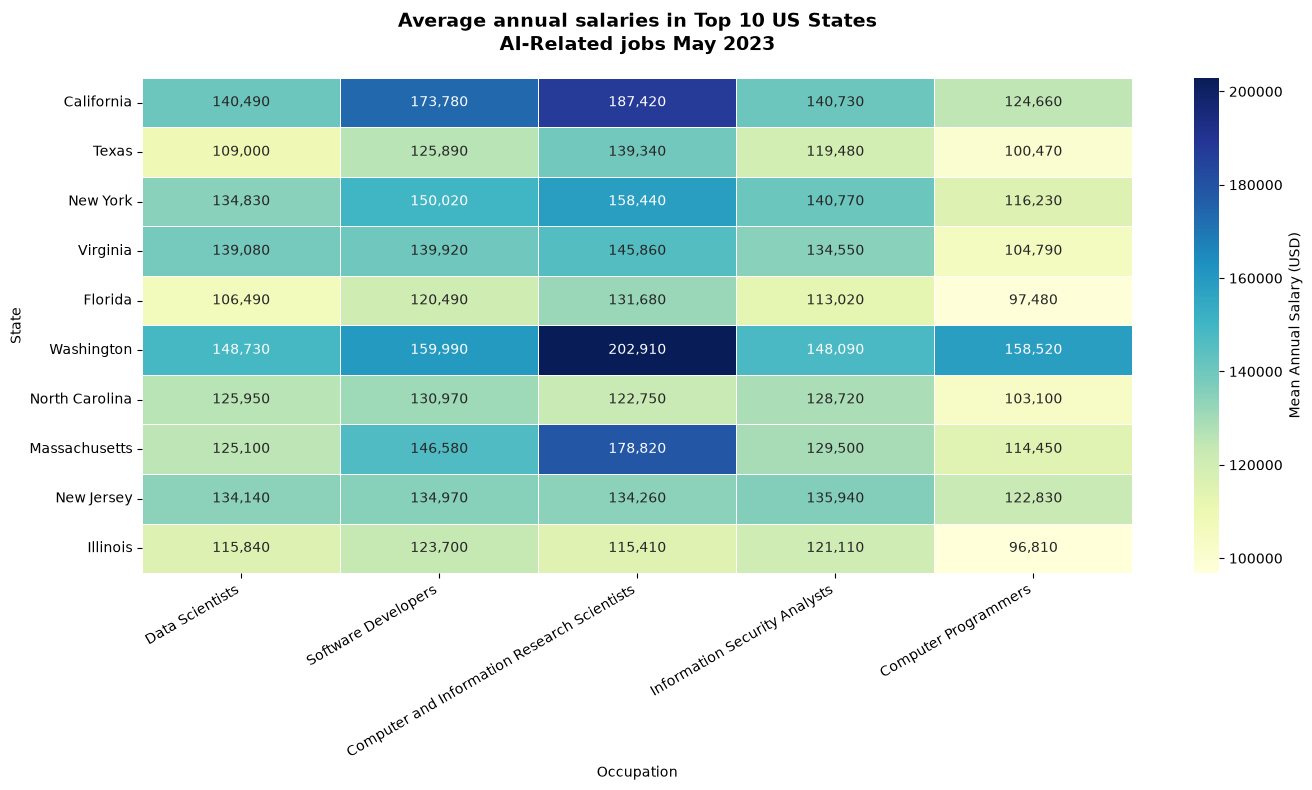

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))

sns.heatmap(
    heatmap_table,
    annot=True,
    fmt=",.0f",
    cmap="YlGnBu",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Mean Annual Salary (USD)"}
)

plt.title(
    "Average annual salaries in Top 10 US States\n"
    "AI-Related jobs May 2023",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.xlabel("Occupation")
plt.ylabel("State")

plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()